In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("carbon_emission_dataset_with_Industry.csv")
df.head()

,Company_ID,Date,Sector,Total_Energy_Consumption_kWh,Renewable_Energy_Consumption_kWh,NonRenewable_Energy_Consumption_kWh,Production_Output_Units,Supply_Chain_Transport_km,Supply_Chain_Transport_Mode,Raw_Material_Usage_kg,...,Carbon_Tax_USD,Process_Efficiency_Percent,Employment_Count,Public_Acceptance_Index,Carbon_Reduction_Strategy,Strategy_Implementation_Cost_USD,Expected_Carbon_Reduction_Percent,Expected_Renewable_Share_Percent,Social_Impact_Score,Industry_Sectors
0,C001,2024-01-01,Manufacturing,53751.61,12766.80,40984.81,3008.90,3814.12,Truck,51334.48,...,338.76,81.07,2128,0.77,Process Reengineering,188176.25,16.79,40.89,0.40,Steel Manufacturing
1,C001,2024-01-02,Manufacturing,170872.89,76733.84,94139.05,4062.25,1199.66,Air,17154.72,...,1073.13,69.26,855,0.77,Efficiency Upgrade,489246.31,12.57,58.19,0.86,Cement Production
2,C001,2024-01-03,Manufacturing,142777.96,75794.17,66983.79,6196.17,3670.57,Truck,56288.43,...,1390.41,90.33,3613,0.48,Carbon Tax Compliance,165061.64,12.11,68.14,0.79,Automotive Industry
3,C001,2024-01-04,Manufacturing,152532.15,20698.80,131833.35,6714.80,2903.63,Ship,21438.17,...,1942.56,79.49,3156,0.85,Efficiency Upgrade,191619.23,5.64,23.30,0.55,Logistics
4,C001,2024-01-05,Manufacturing,81647.43,46657.82,34989.61,8887.31,1916.05,Rail,37694.23,...,472.20,68.63,4915,0.47,Process Reengineering,459129.15,12.99,65.44,0.95,Steel Manufacturing


In [3]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
df.info()
df.describe().T

Shape: (18250, 22)
Missing values: 0
Duplicates: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18250 entries, 0 to 18249
Data columns (total 22 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Company_ID                           18250 non-null  object 
 1   Date                                 18250 non-null  object 
 2   Sector                               18250 non-null  object 
 3   Total_Energy_Consumption_kWh         18250 non-null  float64
 4   Renewable_Energy_Consumption_kWh     18250 non-null  float64
 5   NonRenewable_Energy_Consumption_kWh  18250 non-null  float64
 6   Production_Output_Units              18250 non-null  float64
 7   Supply_Chain_Transport_km            18250 non-null  float64
 8   Supply_Chain_Transport_Mode          18250 non-null  object 
 9   Raw_Material_Usage_kg                18250 non-null  float64
 10  Carbon_Emission_tCO2e_TARGET         18250 

,count,mean,std,min,25%,50%,75%,max
Total_Energy_Consumption_kWh,18250.0,124776.987158,43106.624251,50008.7300,87326.36500,124728.53000,162042.9550,199988.9100
Renewable_Energy_Consumption_kWh,18250.0,43759.097184,24291.666951,5041.2000,24455.50250,38888.00500,59545.0250,119005.2600
NonRenewable_Energy_Consumption_kWh,18250.0,81017.889975,33957.852247,20483.2600,53738.54750,77007.82000,104085.3725,179431.0200
Production_Output_Units,18250.0,5538.963915,2597.576117,1000.4700,3273.99500,5556.40000,7802.0950,9999.7800
Supply_Chain_Transport_km,18250.0,2734.813587,1300.146027,500.3800,1609.12250,2735.02000,3862.7175,4999.8900
Raw_Material_Usage_kg,18250.0,44869.415215,20110.509566,10006.5000,27439.33500,44803.63000,62291.0275,79994.4600
Carbon_Emission_tCO2e_TARGET,18250.0,32.365099,14.482041,6.8149,20.96935,30.15455,41.5204,86.5718
Energy_Cost_USD,18250.0,10600.982042,4532.900551,2524.2000,6979.21000,10001.70000,13621.3850,23880.6900
Carbon_Tax_USD,18250.0,1129.541275,590.407029,155.7400,682.40750,1012.14500,1464.8475,4211.6000
Process_Efficiency_Percent,18250.0,77.623844,10.112534,60.0000,68.88000,77.66000,86.3175,95.0000


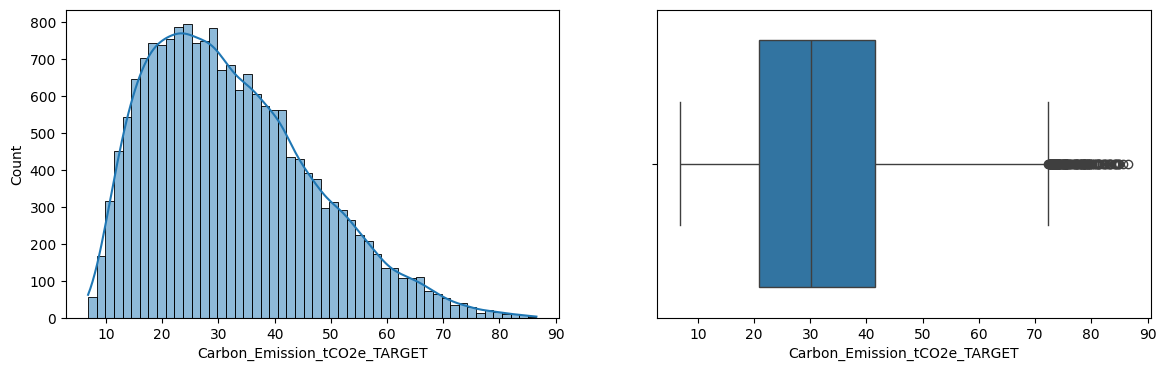

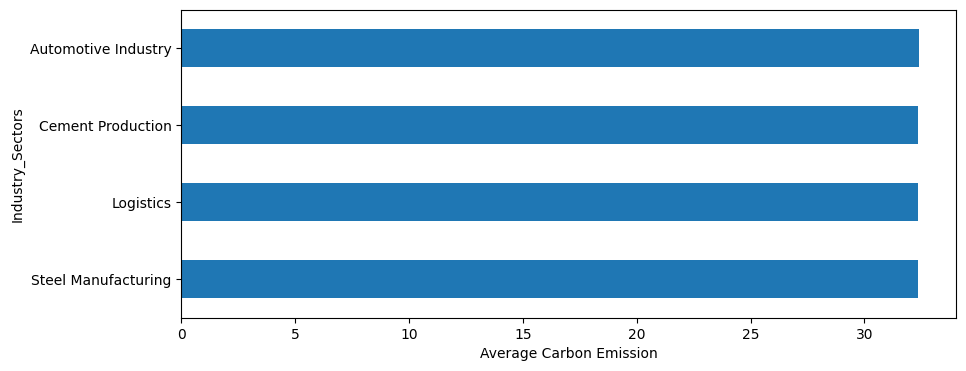

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["Carbon_Emission_tCO2e_TARGET"], kde=True, ax=axes[0])
sns.boxplot(x=df["Carbon_Emission_tCO2e_TARGET"], ax=axes[1])
plt.show()

plt.figure(figsize=(10, 4))
df.groupby("Industry_Sectors")["Carbon_Emission_tCO2e_TARGET"].mean().sort_values().plot(kind="barh")
plt.xlabel("Average Carbon Emission")
plt.show()

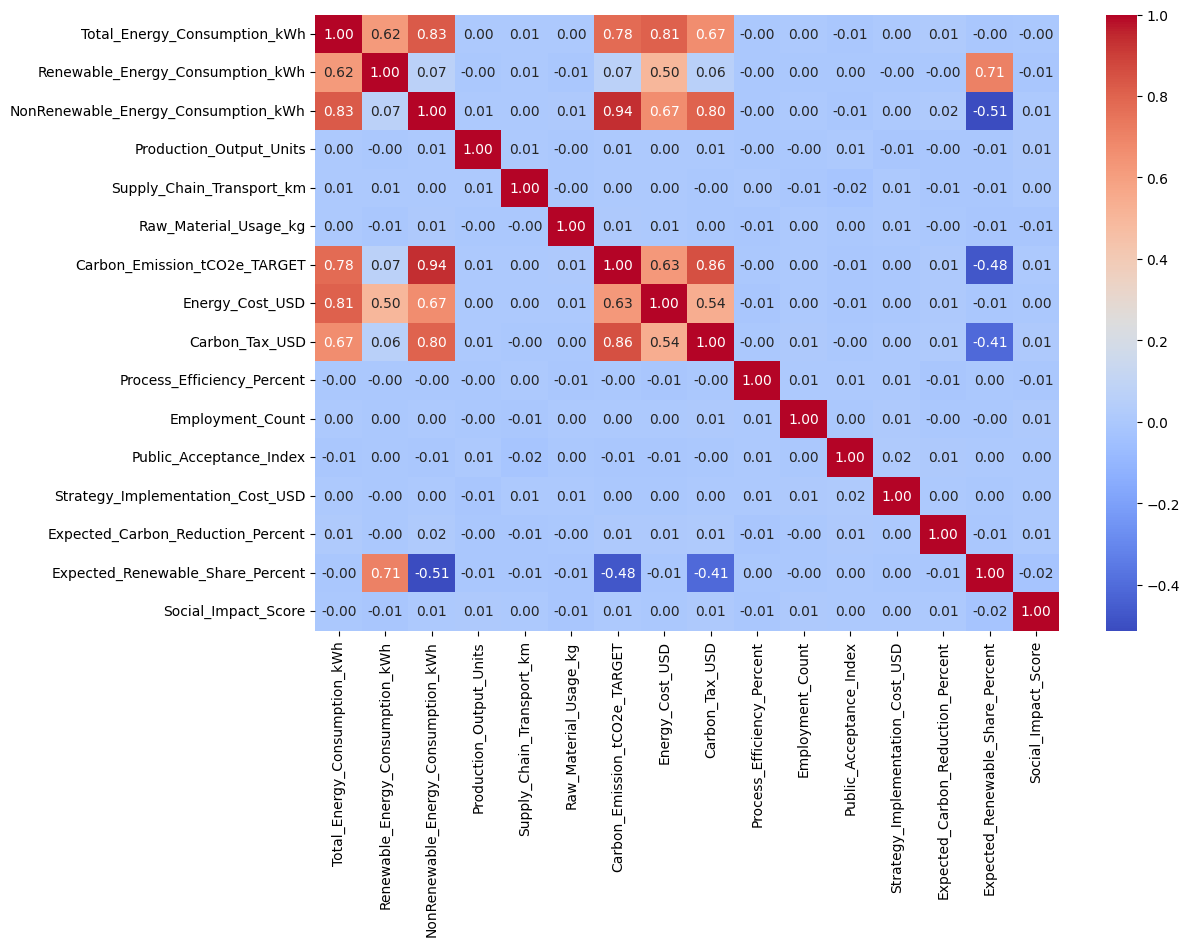

In [5]:
corr = df.select_dtypes(include=[np.number]).corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

In [6]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values(["Company_ID", "Date"]).reset_index(drop=True)

feature_columns = [
    "Total_Energy_Consumption_kWh",
    "Renewable_Energy_Consumption_kWh",
    "NonRenewable_Energy_Consumption_kWh",
    "Production_Output_Units",
    "Supply_Chain_Transport_km",
    "Raw_Material_Usage_kg",
    "Energy_Cost_USD",
    "Carbon_Tax_USD",
    "Process_Efficiency_Percent",
    "Employment_Count",
    "Public_Acceptance_Index",
    "Strategy_Implementation_Cost_USD",
    "Expected_Carbon_Reduction_Percent",
    "Expected_Renewable_Share_Percent",
    "Social_Impact_Score"
]
target_column = "Carbon_Emission_tCO2e_TARGET"

feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

scaled_df = df.copy()
scaled_df[feature_columns] = feature_scaler.fit_transform(df[feature_columns])
scaled_df[[target_column]] = target_scaler.fit_transform(df[[target_column]])


In [7]:
def build_sequences(data, features, target_col, seq_len=60):
    X, y, companies = [], [], []
    for comp in data["Company_ID"].unique():
        sub_df = data[data["Company_ID"] == comp].sort_values("Date")
        feat_vals = sub_df[features].values
        target_vals = sub_df[target_col].values
        for i in range(seq_len - 1, len(sub_df)):
            X.append(feat_vals[i - seq_len + 1 : i + 1])
            y.append([target_vals[i]])
            companies.append(comp)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32), np.array(companies)

X, y, company_ids = build_sequences(scaled_df, feature_columns, target_column)
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (15300, 60, 15)
y shape: (15300, 1)


In [8]:
X_train, X_test, y_train, y_test, _, companies_test = train_test_split(
    X, y, company_ids, test_size=0.2, random_state=42, shuffle=True
)
print("Train shape:", X_train.shape, y_train.shape)
print("Test shape:", X_test.shape, y_test.shape)

Train shape: (12240, 60, 15) (12240, 1)
Test shape: (3060, 60, 15) (3060, 1)


In [9]:
model = tf.keras.Sequential([
    tf.keras.layers.LSTM(128, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="relu")
])

model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.summary()

C:\Users\Bhagyashri\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 128)        │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 125,249 (489.25 KB)

 Trainable params: 125,249 (489.25 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/50
383/383 ━━━━━━━━━━━━━━━━━━━━ 18s 41ms/step - loss: 0.0193 - mae: 0.1033 - val_loss: 0.0035 - val_mae: 0.0466 - learning_rate: 0.0010
Epoch 2/50
383/383 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - loss: 0.0052 - mae: 0.0551 - val_loss: 0.0036 - val_mae: 0.0473 - learning_rate: 0.0010
Epoch 3/50
383/383 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - loss: 0.0046 - mae: 0.0518 - val_loss: 0.0034 - val_mae: 0.0456 - learning_rate: 0.0010
Epoch 4/50
383/383 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - loss: 0.0043 - mae: 0.0503 - val_loss: 0.0033 - val_mae: 0.0452 - learning_rate: 0.0010
Epoch 5/50
383/383 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - loss: 0.0041 - mae: 0.0491 - val_loss: 0.0034 - val_mae: 0.0463 - learning_rate: 0.0010
Epoch 6/50
383/383 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - loss: 0.0039 - mae: 0.0482 - val_loss: 0.0033 - val_mae: 0.0442 - learning_rate: 0.0010
Epoch 7/50
383/383 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - loss: 0.0038 - mae: 0.0475 - val_loss: 0.0033 - val_mae: 0.0448 - learning_rate:

In [11]:
pred_scaled = model.predict(X_test)
predictions = target_scaler.inverse_transform(pred_scaled)
actual = target_scaler.inverse_transform(y_test)

mae = mean_absolute_error(actual, predictions)
rmse = np.sqrt(mean_squared_error(actual, predictions))
r2 = r2_score(actual, predictions)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2: {r2:.4f}")


96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step  
MAE: 3.40
RMSE: 4.36
R2: 0.9079


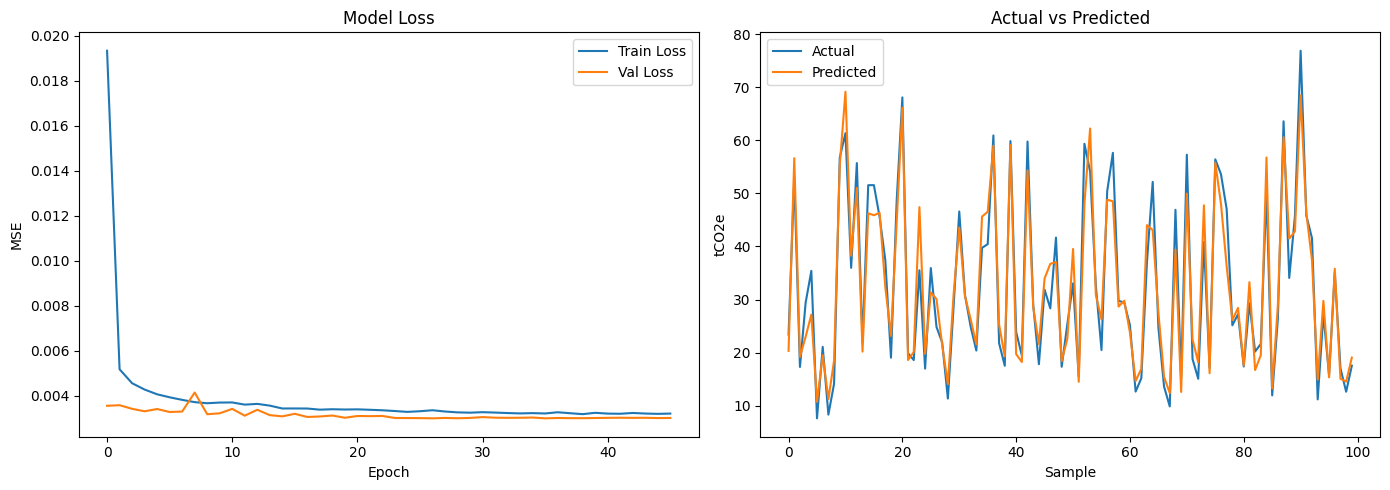

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("Model Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()

axes[1].plot(actual[:100], label="Actual")
axes[1].plot(predictions[:100], label="Predicted")
axes[1].set_title("Actual vs Predicted")
axes[1].set_xlabel("Sample")
axes[1].set_ylabel("tCO2e")
axes[1].legend()

plt.tight_layout()
plt.show()

In [14]:
os.makedirs("models", exist_ok=True)

model.save("models/lstm_model.keras")
joblib.dump(feature_scaler, "models/feature_scaler.joblib")
joblib.dump(target_scaler, "models/target_scaler.joblib")

metrics = {
    "mae": float(mae),
    "rmse": float(rmse),
    "r2": float(r2),
    "num_test_sequences": int(len(X_test)),
    "train_loss": [float(x) for x in history.history["loss"]],
    "val_loss": [float(x) for x in history.history["val_loss"]]
}

with open("models/metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

np.savez(
    "models/test_data.npz",
    X_test=X_test,
    actual=actual,
    predicted=predictions,
    companies_test=companies_test
)

print("Saved in models")

Saved in models
